In [7]:
import numpy as np
import matplotlib as plt
import random
import micrograd
import torch

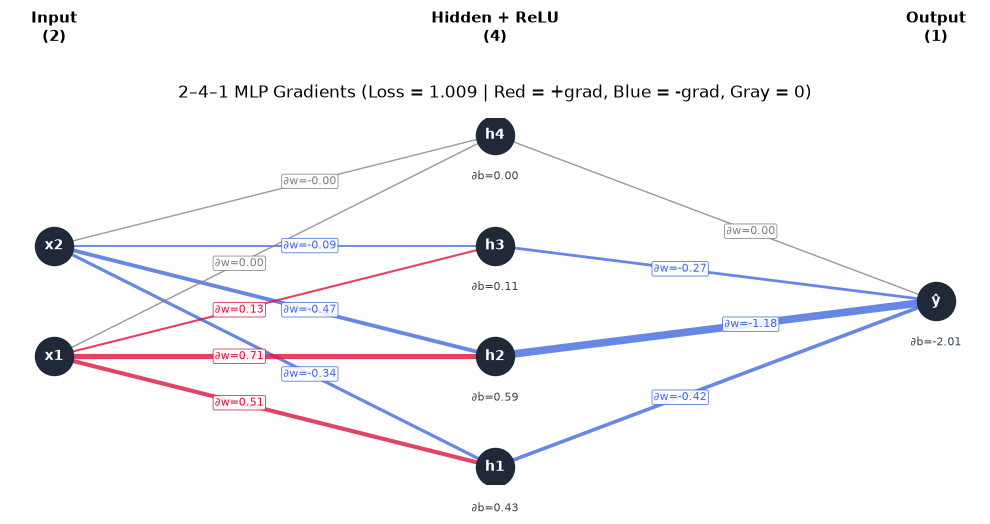

In [27]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np

# 1. Define the 2-4-1 MLP
torch.manual_seed(7)
model = nn.Sequential(
    nn.Linear(2, 4),
    nn.ReLU(),
    nn.Linear(4, 1)
)

# 2. Run one forward & backward pass
x = torch.tensor([[1.2, -0.8]])
target = torch.tensor([[1.0]])
loss = nn.MSELoss()(model(x), target)
loss.backward()

# 3. Extract layer sizes and gradients
linear_layers = [m for m in model if isinstance(m, nn.Linear)]
layer_sizes = [2, 4, 1]
w_grads = [m.weight.grad.detach().numpy() for m in linear_layers]
b_grads = [m.bias.grad.detach().numpy() for m in linear_layers]

# 4. Set up the plot
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.axis("off")

# Compute node coordinates
node_positions = []
for i, size in enumerate(layer_sizes):
    x_pos = i * 3.0
    y_positions = np.linspace(-(size - 1) / 2, (size - 1) / 2, size)
    node_positions.append([(x_pos, y) for y in y_positions])

# Draw edges (weights) colored & scaled by gradient magnitude
max_grad = max(np.abs(g).max() for g in w_grads)
for l_idx, grad_matrix in enumerate(w_grads):
    for out_i, (x2, y2) in enumerate(node_positions[l_idx + 1]):
        for in_i, (x1, y1) in enumerate(node_positions[l_idx]):
            g_val = grad_matrix[out_i, in_i]
            norm_g = abs(g_val) / (max_grad + 1e-8)
            color = "crimson" if g_val > 0 else ("royalblue" if g_val < 0 else "gray")
            
            ax.plot([x1, x2], [y1, y2], color=color, linewidth=1.0 + 4.5 * norm_g, alpha=0.8, zorder=1)
            
            # Place gradient label along the edge (staggered slightly to avoid overlap)
            t = 0.42 if in_i % 2 == 0 else 0.58
            xm = x1 + t * (x2 - x1)
            ym = y1 + t * (y2 - y1)
            ax.text(
                xm, ym, f"∂w={g_val:.2f}", fontsize=8, color=color,
                ha="center", va="center", zorder=4,
                bbox=dict(boxstyle="round,pad=0.15", fc="white", ec=color, lw=0.6, alpha=0.9)
            )

# Draw neurons and annotate bias gradients
layer_names = ["Input\n(2)", "Hidden + ReLU\n(4)", "Output\n(1)"]
for l_idx, layer in enumerate(node_positions):
    for n_idx, (x_pos, y_pos) in enumerate(layer):
        ax.scatter(x_pos, y_pos, s=750, color="#1f2937", zorder=2)
        label = f"x{n_idx+1}" if l_idx == 0 else (f"h{n_idx+1}" if l_idx == 1 else "ŷ")
        ax.text(x_pos, y_pos, label, color="white", fontsize=10, fontweight="bold", ha="center", va="center", zorder=3)
        
        # Show bias gradient below hidden and output neurons
        if l_idx > 0:
            b_val = b_grads[l_idx - 1][n_idx]
            ax.text(x_pos, y_pos - 0.32, f"∂b={b_val:.2f}", fontsize=8, color="#374151", ha="center", va="top")

    ax.text(layer[0][0], max(layer_sizes) / 2 + 0.35, layer_names[l_idx], ha="center", fontsize=11, fontweight="bold")

plt.title(f"2–4–1 MLP Gradients (Loss = {loss.item():.3f} | Red = +grad, Blue = -grad, Gray = 0)", pad=15)
plt.tight_layout()
plt.show()


In [31]:
from graphviz import Digraph
from micrograd.nn import MLP

model = MLP(2, [4, 1])
x = [2.0, -3.0]
out = model(x)

model.zero_grad()
out.backward()

for i, p in enumerate(model.parameters()):
  print(f"param {i:02d} | data: {p.data:+.4f} | grad: {p.grad:+.4f}")


# 4. Graphviz visualization helpers (from Karpathy's micrograd trace_graph.ipynb)
def trace(root):
  nodes, edges = set(), set()

  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)

  build(root)
  return nodes, edges


def draw_dot(root, format="svg", rankdir="LR"):
  nodes, edges = trace(root)
  dot = Digraph(format=format, graph_attr={"rankdir": rankdir})  # LR = left to right

  for n in nodes:
    # Each Value node displays its scalar data and gradient
    dot.node(
        name=str(id(n)),
        label="{ data %.4f | grad %.4f }" % (n.data, n.grad),
        shape="record",
    )
    if n._op:
      # Operation node (+, *, ReLU)
      dot.node(name=str(id(n)) + n._op, label=n._op)
      dot.edge(str(id(n)) + n._op, str(id(n)))

  for n1, n2 in edges:
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot


dot = draw_dot(out)
dot.render("mlp_241_graph", view=True)  # Saves mlp_241_graph.svg and opens it


param 00 | data: +0.6597 | grad: +0.0000
param 01 | data: +0.4914 | grad: +0.0000
param 02 | data: +0.0000 | grad: +0.0000
param 03 | data: +0.3388 | grad: -1.7174
param 04 | data: -0.4122 | grad: +2.5762
param 05 | data: +0.0000 | grad: -0.8587
param 06 | data: +0.0747 | grad: +0.0000
param 07 | data: +0.1314 | grad: +0.0000
param 08 | data: +0.0000 | grad: +0.0000
param 09 | data: +0.8051 | grad: +1.1993
param 10 | data: +0.1570 | grad: -1.7990
param 11 | data: +0.0000 | grad: +0.5997
param 12 | data: +0.5720 | grad: +0.0000
param 13 | data: -0.8587 | grad: +1.9143
param 14 | data: -0.1425 | grad: +0.0000
param 15 | data: +0.5997 | grad: +1.1391
param 16 | data: +0.0000 | grad: +1.0000
